In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

url = "https://realpython.github.io/fake-jobs/"

response = requests.get(url)

print("Status Code:", response.status_code)

Status Code: 200


In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
url = "https://realpython.github.io/fake-jobs/"

response = requests.get(url, timeout=20)

print("Status Code:", response.status_code)

Status Code: 200


In [4]:
print("Website URL:", response.url)
print("Response Status:", response.status_code)

print(response.text[:1000])

Website URL: https://realpython.github.io/fake-jobs/
Response Status: 200
<!DOCTYPE html>
<html>
  <head>
    <meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1">
    <title>Fake Python</title>
    <link rel="stylesheet" href="https://cdn.jsdelivr.net/npm/bulma@0.9.2/css/bulma.min.css">
  </head>
  <body>
  <section class="section">
    <div class="container mb-5">
      <h1 class="title is-1">
        Fake Python
      </h1>
      <p class="subtitle is-3">
        Fake Jobs for Your Web Scraping Journey
      </p>
    </div>
    <div class="container">
    <div id="ResultsContainer" class="columns is-multiline">
    <div class="column is-half">
<div class="card">
  <div class="card-content">
    <div class="media">
      <div class="media-left">
        <figure class="image is-48x48">
          <img src="https://files.realpython.com/media/real-python-logo-thumbnail.7f0db70c2ed2.jpg?__no_cf_polish=1" alt="Real Python Logo">
        </figure>
 

In [5]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.text)

Fake Python


In [6]:
job_cards = soup.find_all("div", class_="card-content")

print("Total Job Cards:", len(job_cards))

print(job_cards[0].prettify())

Total Job Cards: 100
<div class="card-content">
 <div class="media">
  <div class="media-left">
   <figure class="image is-48x48">
    <img alt="Real Python Logo" src="https://files.realpython.com/media/real-python-logo-thumbnail.7f0db70c2ed2.jpg?__no_cf_polish=1"/>
   </figure>
  </div>
  <div class="media-content">
   <h2 class="title is-5">
    Senior Python Developer
   </h2>
   <h3 class="subtitle is-6 company">
    Payne, Roberts and Davis
   </h3>
  </div>
 </div>
 <div class="content">
  <p class="location">
   Stewartbury, AA
  </p>
  <p class="is-small has-text-grey">
   <time datetime="2021-04-08">
    2021-04-08
   </time>
  </p>
 </div>
 <footer class="card-footer">
  <a class="card-footer-item" href="https://www.realpython.com" target="_blank">
   Learn
  </a>
  <a class="card-footer-item" href="https://realpython.github.io/fake-jobs/jobs/senior-python-developer-0.html" target="_blank">
   Apply
  </a>
 </footer>
</div>



In [7]:
jobs = []

for job in job_cards:

    job_title = job.find("h2", class_="title").text.strip()

    company_name = job.find("h3", class_="company").text.strip()

    location = job.find("p", class_="location").text.strip()

    description = job.find("div", class_="description")

    if description:
        description = description.text.strip()
    else:
        description = ""

    jobs.append({
        "Job Title": job_title,
        "Company Name": company_name,
        "Location": location,
        "Description": description
    })

print("Total Jobs Extracted:", len(jobs))

Total Jobs Extracted: 100


In [8]:
df = pd.DataFrame(jobs)

df.head()

,Job Title,Company Name,Location,Description
0,Senior Python Developer,"Payne, Roberts and Davis","Stewartbury, AA",
1,Energy engineer,Vasquez-Davidson,"Christopherville, AA",
2,Legal executive,"Jackson, Chambers and Levy","Port Ericaburgh, AA",
3,Fitness centre manager,Savage-Bradley,"East Seanview, AP",
4,Product manager,Ramirez Inc,"North Jamieview, AP",


In [9]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (100, 4)

Column Names:
Index(['Job Title', 'Company Name', 'Location', 'Description'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Job Title     100 non-null    object
 1   Company Name  100 non-null    object
 2   Location      100 non-null    object
 3   Description   100 non-null    object
dtypes: object(4)
memory usage: 3.3+ KB


In [10]:
df.isnull().sum()

Job Title       0
Company Name    0
Location        0
Description     0
dtype: int64

In [11]:
df = df.drop_duplicates()

df = df.fillna("Not Available")

df["Job Title"] = df["Job Title"].str.strip()

df["Company Name"] = df["Company Name"].str.strip()

df["Location"] = df["Location"].str.strip()

df.head()

,Job Title,Company Name,Location,Description
0,Senior Python Developer,"Payne, Roberts and Davis","Stewartbury, AA",
1,Energy engineer,Vasquez-Davidson,"Christopherville, AA",
2,Legal executive,"Jackson, Chambers and Levy","Port Ericaburgh, AA",
3,Fitness centre manager,Savage-Bradley,"East Seanview, AP",
4,Product manager,Ramirez Inc,"North Jamieview, AP",


In [12]:
df.to_csv("job_portal_dataset.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [13]:
print("Total Jobs:", len(df))

Total Jobs: 100


In [14]:
company_jobs = df["Company Name"].value_counts()

print(company_jobs.head(10))

Company Name
Garcia PLC                    2
Vasquez-Davidson              1
Payne, Roberts and Davis      1
Jackson, Chambers and Levy    1
Savage-Bradley                1
Rogers-Yates                  1
Ramirez Inc                   1
Kramer-Klein                  1
Meyers-Johnson                1
Hughes-Williams               1
Name: count, dtype: int64


In [15]:
location_jobs = df["Location"].value_counts()

print(location_jobs.head(10))

Location
Stewartbury, AA          1
Christopherville, AA     1
Port Ericaburgh, AA      1
East Seanview, AP        1
North Jamieview, AP      1
Davidville, AP           1
South Christopher, AE    1
Port Jonathan, AE        1
Osbornetown, AE          1
Scotttown, AP            1
Name: count, dtype: int64


In [16]:
title_jobs = df["Job Title"].value_counts()

print(title_jobs.head(10))

Job Title
Python Programmer (Entry-Level)            3
Legal executive                            2
Materials engineer                         2
Software Developer (Python)                2
Manufacturing systems engineer             2
Back-End Web Developer (Python, Django)    2
Futures trader                             2
Textile designer                           1
Product manager                            1
Medical technical officer                  1
Name: count, dtype: int64


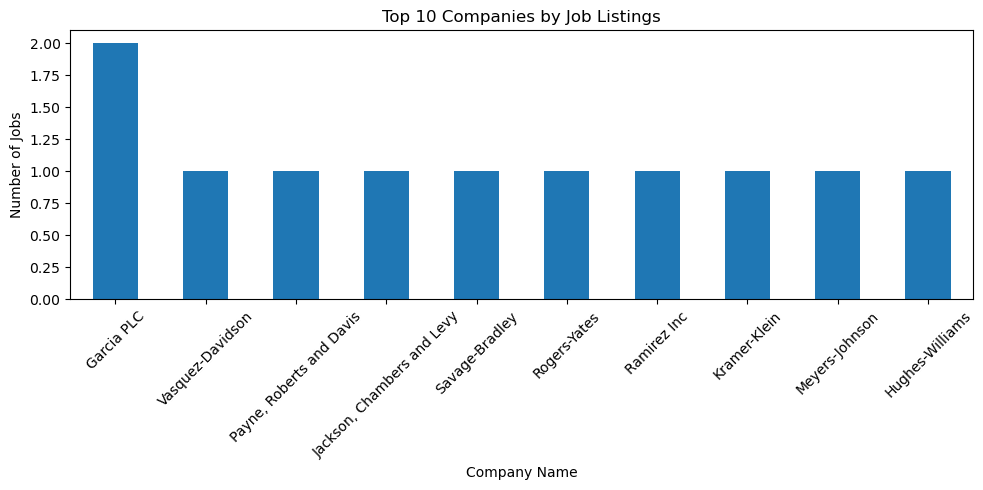

In [17]:
company_jobs.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Companies by Job Listings")
plt.xlabel("Company Name")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

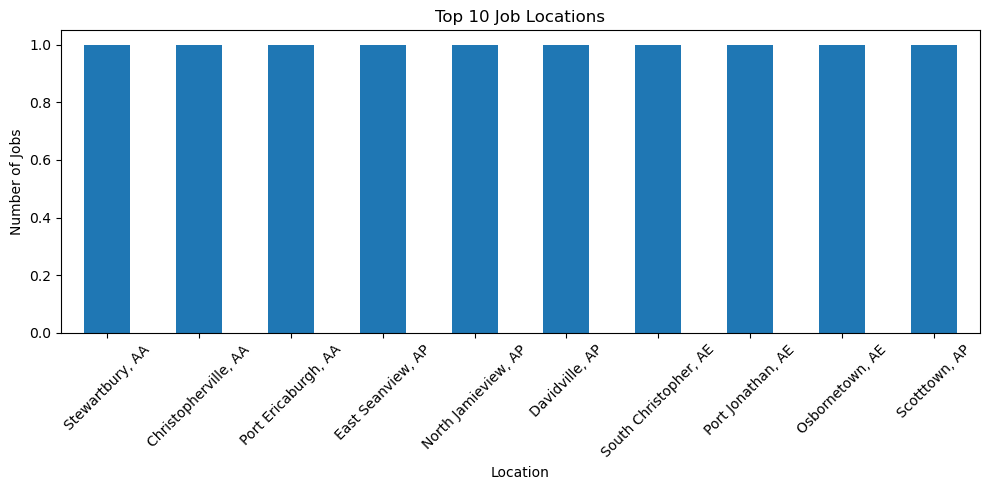

In [18]:
location_jobs.head(10).plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Top 10 Job Locations")
plt.xlabel("Location")
plt.ylabel("Number of Jobs")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [19]:
jobs = []

for job in job_cards:

    job_title = job.find("h2", class_="title").get_text(strip=True)

    company_name = job.find("h3", class_="company").get_text(strip=True)

    location = job.find("p", class_="location").get_text(strip=True)

    jobs.append({
        "Job Title": job_title,
        "Company Name": company_name,
        "Location": location
    })

print("Total Jobs Extracted:", len(jobs))

Total Jobs Extracted: 100
